In [2]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
from pathlib import Path

In [9]:
def amplia(imagen, factor=2):
    """
    Zoom simple x2.
    """
    R=factor
    resimg = np.repeat(np.repeat(imagen, R, axis=0), R, axis=1)
    return resimg

In [10]:
def interpolacion_bilineal_opencv(imagen, scale_factor):
    """
    Interpolación bilineal usando OpenCV.
    """
    h, w = imagen.shape[:2]
    new_w = int(w * scale_factor)
    new_h = int(h * scale_factor)
    
    return cv.resize(imagen, (new_w, new_h), interpolation=cv.INTER_NEAREST)


In [13]:
img = np.array([
            [12,17,32], 
            [26,17,40], 
            [14,20,27],
        ])


res = amplia(img)

In [22]:
img = cv.imread("satelite_nocturno.jpg", cv.IMREAD_GRAYSCALE)
res = amplia(img)
print(res)
cv.imwrite("ej2.png", res) 

[[139 139 142 ... 125 127 127]
 [139 139 142 ... 125 127 127]
 [141 141 142 ... 133 133 133]
 ...
 [ 55  55  53 ...  55  56  56]
 [ 55  55  54 ...  57  56  56]
 [ 55  55  54 ...  57  56  56]]


True

In [23]:
#TAREA 27

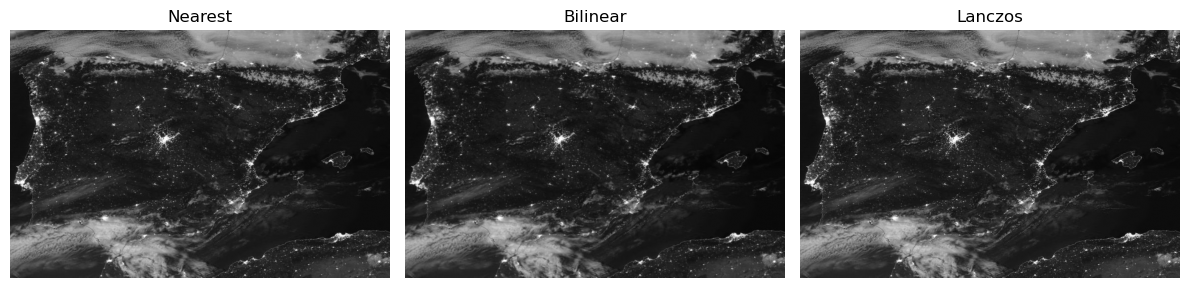

In [24]:
scale = 2.0
h, w = img.shape[:2]
new_size = (int(w*scale), int(h*scale))

nn  = cv.resize(img, new_size, interpolation=cv.INTER_NEAREST)
bil = cv.resize(img, new_size, interpolation=cv.INTER_LINEAR)
lan = cv.resize(img, new_size, interpolation=cv.INTER_LANCZOS4)

plt.figure(figsize=(12,4))
plt.subplot(1,3,1); plt.imshow(nn, cmap='gray');  plt.title("Nearest"); plt.axis("off")
plt.subplot(1,3,2); plt.imshow(bil, cmap='gray'); plt.title("Bilinear"); plt.axis("off")
plt.subplot(1,3,3); plt.imshow(lan, cmap='gray'); plt.title("Lanczos");  plt.axis("off")
plt.tight_layout(); plt.show()


In [25]:
#TAREA 28

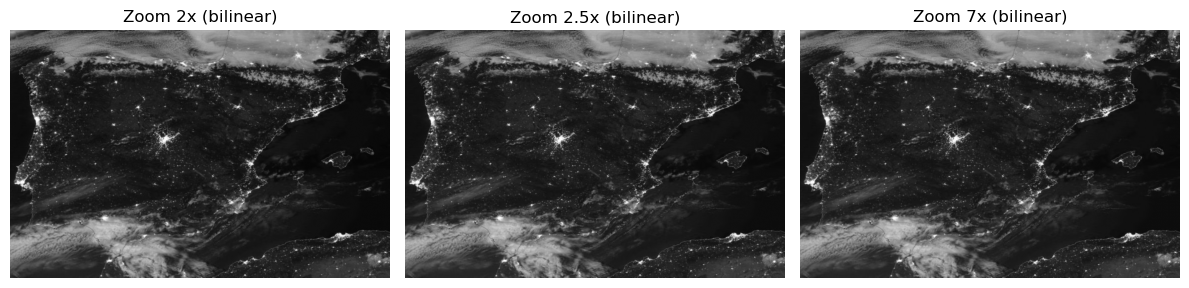

In [26]:
factores = [2, 2.5, 7]

plt.figure(figsize=(12,4))
i = 1

for f in factores:
    h, w = img.shape[:2]
    new_size = (int(w*f), int(h*f))
    res = cv.resize(img, new_size, interpolation=cv.INTER_LINEAR)
    plt.subplot(1,3,i)
    plt.imshow(res, cmap='gray')
    plt.title(f"Zoom {f}x (bilinear)")
    plt.axis("off")
    i += 1

plt.tight_layout()
plt.show()


In [27]:
#Cuanto mayor es el zoom bilinear, más borrosa y lavada aparece la imagen

In [28]:
#TAREA 29

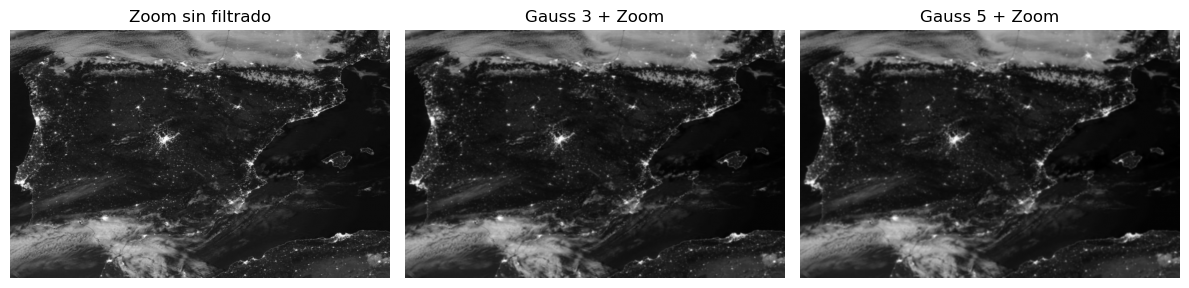

In [29]:
h, w = img.shape[:2]
factor = 4
new_size = (int(w*factor), int(h*factor))

img_sin = cv.resize(img, new_size, interpolation=cv.INTER_LINEAR)

img_g3 = cv.GaussianBlur(img, (3,3), 0)
img_g5 = cv.GaussianBlur(img, (5,5), 0)

img_g3_zoom = cv.resize(img_g3, new_size, interpolation=cv.INTER_LINEAR)
img_g5_zoom = cv.resize(img_g5, new_size, interpolation=cv.INTER_LINEAR)

plt.figure(figsize=(12,4))
plt.subplot(1,3,1); plt.imshow(img_sin, cmap='gray');    plt.title("Zoom sin filtrado"); plt.axis("off")
plt.subplot(1,3,2); plt.imshow(img_g3_zoom, cmap='gray'); plt.title("Gauss 3 + Zoom");   plt.axis("off")
plt.subplot(1,3,3); plt.imshow(img_g5_zoom, cmap='gray'); plt.title("Gauss 5 + Zoom");   plt.axis("off")
plt.tight_layout(); plt.show()
